# Bước 5. Data Visualization: sơ đồ quy trình, hình dữ liệu, hình mô hình và bảng mô tả cho bài báo

Bước 4 vẽ hình để KHÁM PHÁ. Bước này vẽ các hình ở chất lượng nộp bài (PDF vector, đúng bề rộng trang LNCS) và ghi bảng mô tả ba nhóm địa chỉ.
Bài báo dự kiến dùng sáu hình của bước này (Fig. 1 tới Fig. 6) cùng các hình kết quả của Bước 6 khi cần. Các hình còn lại vẫn được lưu đủ chất lượng trong `Paper/figs` để nhóm dùng cho slide hoặc đưa vào bài khi còn trang.
Môn ADY201m yêu cầu người đọc phải THẤY được ba góc nhìn của dữ liệu: địa lý (ở đâu), chu kỳ (khi nào) và phân bố (nhiều hay ít). Ba hình ở mục 5.5, 5.6 và 5.7 trả lời đúng ba góc nhìn ấy. Bộ PhiUSIIL không có cột thời gian, nên góc nhìn chu kỳ được thay bằng thứ tự dòng trong tệp (giống Bước 4, mục 4.7).
Mỗi hình chỉ nói MỘT ý. Bảng dưới cho biết vì sao chọn từng dạng biểu đồ.

| STT | Mục | Hình trong bài báo | Dạng biểu đồ | Ý cần thấy |
|---|---|---|---|---|
| 1 | 5.1 | Fig. 1 | Sơ đồ nhiều tầng | Nghiên cứu gồm những bước nào, phần nào là đóng góp của nhóm |
| 2 | 5.2 | Fig. 2 | Cột ngang xếp chồng 100% | Hai lớp khác nhau ở dạng địa chỉ: tiền tố `https://www.` và đường dẫn |
| 3 | 5.3 | Chỉ trong notebook | Cột xếp chồng theo khoảng điểm | Chỉ số tương đồng bằng 100 gần như chỉ có ở địa chỉ hợp lệ |
| 4 | 5.4 | Chỉ trong notebook | Biểu đồ chấm nối đôi | Trang lừa đảo gần như trống khi được lưu |
| 5 | 5.5 | Fig. 3 | Bản đồ thế giới tô màu theo TLD mã nước | ĐỊA LÝ: TLD của nước nào bị dùng nhiều để lừa đảo |
| 6 | 5.6 | Chỉ trong notebook | Bản đồ nhiệt chỉ số x khối dòng | CHU KỲ (thay bằng thứ tự trong tệp): tệp có xếp theo đợt hay không |
| 7 | 5.7 | Fig. 4 | Biểu đồ hộp, ba nhóm, trục log | PHÂN BỐ: độ dài địa chỉ chồng nhau ở trang chủ, độ lớn trang thì không |
| 8 | 5.8 | Fig. 5 | Cột ngang xếp chồng theo nhóm cột | Bảy bộ đặc trưng gồm những gì, bộ nào còn thấy tiền tố |
| 9 | 5.9 | Fig. 6 | Bản đồ nhiệt mô hình x bộ đặc trưng | Điểm số trên trang chủ chỉ sụp ở bộ không thấy tiền tố, với mọi mô hình |

Mục 5.10 ghi bảng mô tả ba nhóm địa chỉ (`Paper/tables/table_groups.tex`). Mục 5.11 và 5.12 lưu các con số để dò với bài báo.

Quy tắc vẽ: chữ trong hình bằng tiếng Anh, màu đen, cùng phông Computer Modern với bài báo. Không đặt tiêu đề bên trong hình, bỏ viền trên và viền phải, nhãn không đè lên đường.
Hình được vẽ đúng bề rộng in (4,8 inch, khoảng 12,2 cm) nên cỡ chữ trong mã chính là cỡ chữ trên trang. Mọi chữ trong hình từ 7 pt trở lên: muốn chữ to thì tăng cỡ chữ trong mã, không thu nhỏ hình.
Màu dùng thống nhất: xanh là hợp lệ, san hô là lừa đảo, san hô đậm là lừa đảo có đường dẫn. Trong sơ đồ, khối nền san hô là phần đóng góp của nhóm.

Ô dưới nạp thư viện, đọc bảng mô hình và nhóm đặc trưng của Bước 2, đọc kết quả thang đặc trưng của Bước 6, chia địa chỉ thành ba nhóm và định nghĩa ba hàm phụ.
Hàm `note` ghi lại con số sẽ trích trong bài báo (chạy lại ô thì thay, không ghi trùng). Hàm `save_paper` lưu hình thành PDF đúng kích thước đã khai báo trong `Paper/figs` và PNG trong `Figures`. Hàm `draw_arrow` vẽ mũi tên cho sơ đồ. Các màu phụ được khai báo ngay trong ô này để notebook không phụ thuộc phiên bản `style.py`. Ô này không in gì.

In [3]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Patch, Polygon
from matplotlib.collections import PatchCollection
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap
from style import *
setup()
plt.rcParams.update({"font.size": 7.5})                                         # phông Computer Modern và chữ màu đen đã đặt trong style.setup()
os.makedirs("../Paper/tables", exist_ok=True)
os.makedirs("../Paper/figs", exist_ok=True)
PAGE_WIDTH = 4.8                                                                # bề rộng phần chữ của trang LNCS, tính bằng inch
NAVY, GREY, SKY_L, OURS_L, DARK = "#1F3A5F", "#A9B8C6", "#DCEAF7", "#F9D9CE", "#9E2A10"   # màu phụ khai báo tại đây, không phụ thuộc phiên bản style.py
CMAP_CORAL = LinearSegmentedColormap.from_list("coral", ["#FDF1EC", OURS_L, OURS])           # thang một tông: càng đậm càng nhiều lừa đảo (đầu nhạt vẫn khác màu xám)
CMAP_DIVERGE = LinearSegmentedColormap.from_list("diverge", [SKY, "#FFFFFF", OURS])        # thang hai phía: xanh là thấp hơn mức chung, san hô là cao hơn
NUMBERS = []                                                                    # các con số sẽ trích trong bài báo
df = pd.read_parquet("../Outputs/phishing_model_table.parquet")
groups = json.load(open("../Outputs/feature_groups.json", encoding="utf-8"))
ladder = pd.read_csv("../Outputs/results_ladder.csv")
GROUPS = ["Legitimate", "Phishing, homepage", "Phishing, with path"]            # ba nhóm của Bước 4, mục 4.8
df["group"] = np.select([df.phishing == 0, df.homepage_only == 1], GROUPS[:2], GROUPS[2])
GROUP_COLOR = dict(zip(GROUPS, [SKY, OURS, DARK]))


def note(section, name, value):
    """Ghi lại một con số sẽ được trích trong phần chữ của bài báo; chạy lại ô thì thay, không ghi trùng."""
    NUMBERS[:] = [r for r in NUMBERS if not (r["paper_section"] == section and r["quantity"] == name)]
    NUMBERS.append(dict(paper_section=section, quantity=name, value=value))


def save_paper(fig, name):
    """Lưu hình cho bài báo: PDF vector đúng kích thước khai báo (không cắt mép) và PNG để xem nhanh."""
    with plt.rc_context({"savefig.bbox": "standard"}):
        fig.savefig(f"../Paper/figs/{name}.pdf", facecolor="white")
    save(fig, name)


def draw_arrow(ax, start, end, lw=1.0):
    """Mũi tên đen nét liền từ start tới end (toạ độ của trục)."""
    ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="-|>", color="black", lw=lw, mutation_scale=8, shrinkA=0, shrinkB=0), zorder=4)

## 5.1 Sơ đồ quy trình nhiều tầng (Fig. 1 của bài báo)
**Vì sao chọn dạng này:** sơ đồ một hàng chỉ kể được thứ tự các bước. Sơ đồ nhiều tầng kể thêm được mỗi tầng gồm những gì và phần nào là đóng góp của nhóm.

Ô dưới vẽ sáu tầng từ trên xuống: nguồn dữ liệu, chuẩn bị, cách chia và nhóm con, mô hình, đánh giá, phát hiện. Tên tầng nằm bên trái. Mỗi tầng tối đa bốn khối, mỗi khối một dòng chữ.
Cách đọc: đọc từ trên xuống theo mũi tên giữa các tầng. Trong tầng có mũi tên ngang thì các khối là các bước nối tiếp nhau, không có mũi tên thì các khối đứng song song.
Khối bo góc nền trắng là dữ liệu, khối nền xanh nhạt là bước quen thuộc, khối nền san hô là phần đóng góp của bài: kiểm tra lỗi trong cột của tác giả, bộ đặc trưng không thấy tiền tố, nhóm trang chủ, phép thử TLD chưa thấy, quy tắc một dòng, thang bảy bộ đặc trưng, chỉ số bắt được ở 1% báo động giả và ba phát hiện. Ô in thêm bề rộng chữ so với khối để chắc không chữ nào tràn.

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Chữ rộng nhất chiếm 84% bề rộng khối (phải dưới 88%)
Ba dòng chữ rộng nhất: [(81, 'Homepage subset'), (84, 'Audit author columns'), (84, 'Seven feature sets')]


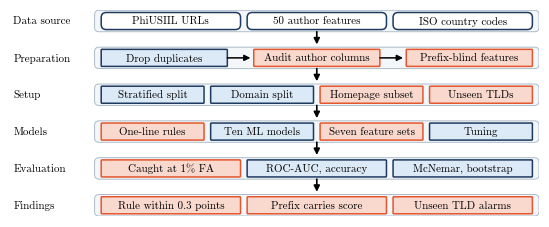

In [5]:
TIERS = [   # (tên tầng, nối tiếp hay song song, danh sách khối: (chữ, kiểu))
    ("Data source", False, [("PhiUSIIL URLs", "data"), ("50 author features", "data"), ("ISO country codes", "data")]),
    ("Preparation", True, [("Drop duplicates", "step"), ("Audit author columns", "ours"), ("Prefix-blind features", "ours")]),
    ("Setup", False, [("Stratified split", "step"), ("Domain split", "step"), ("Homepage subset", "ours"), ("Unseen TLDs", "ours")]),
    ("Models", False, [("One-line rules", "ours"), ("Ten ML models", "step"), ("Seven feature sets", "ours"), ("Tuning", "step")]),
    ("Evaluation", False, [("Caught at 1% FA", "ours"), ("ROC-AUC, accuracy", "step"), ("McNemar, bootstrap", "step")]),
    ("Findings", False, [("Rule within 0.3 points", "ours"), ("Prefix carries score", "ours"), ("Unseen TLD alarms", "ours")]),
]
BAND_H, GAP_V, BLOCK_H, PAD = 1.95, 1.4, 1.55, 0.6         # đơn vị vẽ: 1 đơn vị = 0,1 inch
LEFT, RIGHT = 7.6, 48.0                                    # dải khối nằm giữa hai mốc này, bên trái là tên tầng
height = len(TIERS) * BAND_H + (len(TIERS) - 1) * GAP_V
fig = plt.figure(figsize=(PAGE_WIDTH, height / 10))
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, 48)
ax.set_ylim(0, height)
ax.axis("off")
STYLE = {"data": dict(fill="white", edge=NAVY, rounded=True), "step": dict(fill=SKY_L, edge=NAVY, rounded=False), "ours": dict(fill=OURS_L, edge=OURS, rounded=False)}
labels = []
for i, (tier, chained, blocks) in enumerate(TIERS):
    y = height - (i + 1) * BAND_H - i * GAP_V                                   # mép dưới của dải
    ax.add_patch(FancyBboxPatch((LEFT, y), RIGHT - LEFT, BAND_H, boxstyle="round,pad=0,rounding_size=0.4", fc="#F3F7FA", ec=GREY, lw=0.6, zorder=1))
    ax.text(0.2, y + BAND_H / 2, tier, ha="left", va="center", fontsize=7.2)
    gap = 2.4 if chained else PAD                                               # khối nối tiếp cần khe rộng để thân mũi tên hiện rõ
    w = (RIGHT - LEFT - 2 * PAD - (len(blocks) - 1) * gap) / len(blocks)
    for j, (text, kind) in enumerate(blocks):
        x = LEFT + PAD + j * (w + gap)
        style = STYLE[kind]
        corner = 0.3 * BLOCK_H if style["rounded"] else 0.05 * BLOCK_H
        ax.add_patch(FancyBboxPatch((x, y + (BAND_H - BLOCK_H) / 2), w, BLOCK_H, boxstyle=f"round,pad=0,rounding_size={corner}", fc=style["fill"], ec=style["edge"], lw=1.0, zorder=2))
        labels.append((ax.text(x + w / 2, y + BAND_H / 2, text, ha="center", va="center", fontsize=7.2, zorder=3), w))
        if chained and j < len(blocks) - 1:
            draw_arrow(ax, (x + w, y + BAND_H / 2), (x + w + gap - 0.3, y + BAND_H / 2))            # từ mép khối tới sát mép khối kế tiếp
    if i < len(TIERS) - 1:
        draw_arrow(ax, ((LEFT + RIGHT) / 2, y), ((LEFT + RIGHT) / 2, y - GAP_V + 0.25), lw=1.1)    # từ mép dưới của tầng tới sát mép trên của tầng kế tiếp
# Kiểm tra bằng số: không dòng chữ nào rộng quá 88% bề rộng của khối chứa dòng ấy.
fig.canvas.draw()
to_data = ax.transData.inverted()
widest = max(label.get_window_extent().transformed(to_data).width / w for label, w in labels)
print("Chữ rộng nhất chiếm %.0f%% bề rộng khối (phải dưới 88%%)" % (100 * widest))
print("Ba dòng chữ rộng nhất:", sorted([(round(100 * label.get_window_extent().transformed(to_data).width / w), label.get_text()) for label, w in labels])[-3:])
save_paper(fig, "fig_pipeline")

## 5.2 Hai lớp khác nhau ở dạng địa chỉ (Fig. 2 của bài báo)
**Vì sao chọn dạng này:** mỗi lớp được chia thành bốn dạng địa chỉ cộng lại đủ 100%, nên cột ngang xếp chồng cho thấy ngay mỗi lớp nằm ở đâu. Hai cột đặt chồng lên nhau để so trực tiếp.

Ô dưới chia mỗi địa chỉ theo hai câu hỏi: có bắt đầu bằng `https://www.` không, và có đường dẫn sau tên miền không. Mỗi lớp là một cột, mỗi màu là một dạng.
Cách đọc: cột hợp lệ là một khối xanh liền (100% là `https://www.` không đường dẫn). Ở cột lừa đảo, phần xanh chỉ còn một vạch mảnh 0,62% ở mép trái: đó là phần duy nhất mà quy tắc hai điều kiện ("không bắt đầu bằng `https://www.` hoặc có đường dẫn") bỏ sót. 57,89% địa chỉ lừa đảo vừa không có `https://www.` vừa có đường dẫn.

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


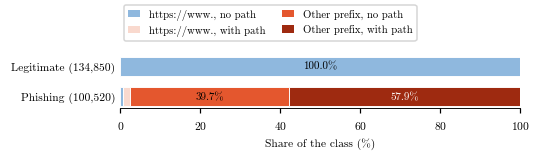

            https://www., no path  https://www., with path  Other prefix, no path  Other prefix, with path
Legitimate                 100.00                     0.00                   0.00                     0.00
Phishing                     0.62                     1.81                  39.68                    57.89


In [6]:
SHAPES = [   # (chữ trong chú thích, điều kiện, màu)
    ("https://www., no path", (df.starts_https_www == 1) & (df.has_path == 0), SKY),
    ("https://www., with path", (df.starts_https_www == 1) & (df.has_path == 1), OURS_L),
    ("Other prefix, no path", (df.starts_https_www == 0) & (df.has_path == 0), OURS),
    ("Other prefix, with path", (df.starts_https_www == 0) & (df.has_path == 1), DARK),
]
shape_table = pd.DataFrame({label: [100 * mask[df.phishing == k].mean() for k in (0, 1)] for label, mask, _ in SHAPES}, index=["Legitimate", "Phishing"])
fig, ax = plt.subplots(figsize=(PAGE_WIDTH, 1.35), layout="constrained")
for row, cls in enumerate(["Phishing", "Legitimate"]):
    left = 0
    for label, _, color in SHAPES:
        width = shape_table.loc[cls, label]
        ax.barh(row, width, left=left, height=0.62, color=color, edgecolor="white", lw=0.6)
        if width >= 4:
            ax.text(left + width / 2, row, f"{width:.1f}%", ha="center", va="center", fontsize=7.2, color="white" if color == DARK else "black")
        left += width
ax.set_yticks([0, 1])
ax.set_yticklabels([f"Phishing ({(df.phishing == 1).sum():,})", f"Legitimate ({(df.phishing == 0).sum():,})"], fontsize=7.5)
ax.set_xlim(0, 100)
ax.set_xlabel("Share of the class (%)", fontsize=7.5)
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
fig.legend(handles=[Patch(facecolor=c, label=l) for l, _, c in SHAPES], loc="outside upper center", ncol=2, fontsize=7, handlelength=1.1, columnspacing=1.6)
save_paper(fig, "fig_url_shapes")
shape_table.round(2).to_csv("../Outputs/table_url_shapes.csv")
print(shape_table.round(2).to_string())

## 5.3 Chỉ số tương đồng theo khoảng điểm (chỉ trong notebook)
**Vì sao chọn dạng này:** chỉ số tương đồng chạy từ 0 tới 100, chia thành khoảng 10 điểm thì cột xếp chồng cho thấy cả số lượng lẫn lớp trong từng khoảng. Điểm đúng bằng 100 được tách thành một cột riêng vì đây chính là lối tắt.

Ô dưới đếm số địa chỉ (nghìn) trong từng khoảng, tô san hô cho lừa đảo và xanh cho hợp lệ. Con số trên đầu cột là tổng số địa chỉ của khoảng.
Cách đọc: mọi địa chỉ hợp lệ (134.850) nằm ở cột 100, trong khi chỉ 786 địa chỉ lừa đảo (0,78%) có điểm 100. Các khoảng dưới 100 toàn là lừa đảo, đông nhất ở khoảng 60 tới 69. Quy tắc "điểm dưới 100 là lừa đảo" vì vậy gần như tách trọn hai lớp mà không cần học gì.

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


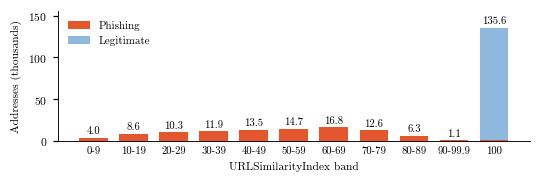

      legitimate_thousands  phishing_thousands
band                                          
0                     0.00               4.002
10                    0.00               8.584
20                    0.00              10.274
30                    0.00              11.863
40                    0.00              13.515
50                    0.00              14.727
60                    0.00              16.824
70                    0.00              12.611
80                    0.00               6.254
90                    0.00               1.080
100                 134.85               0.786


In [8]:
bins = list(range(0, 100, 10))                                                  # mười khoảng [0, 10) ... [90, 100) và một cột riêng cho đúng 100
band = np.where(df.URLSimilarityIndex >= 100, "100", (df.URLSimilarityIndex // 10 * 10).clip(upper=90).astype(int).astype(str))
counts = pd.crosstab(pd.Series(band, name="band"), df.phishing).reindex([str(b) for b in bins] + ["100"]).fillna(0) / 1000
fig, ax = plt.subplots(figsize=(PAGE_WIDTH, 1.55), layout="constrained")
x = np.arange(len(counts))
ax.bar(x, counts[1], color=OURS, width=0.72, label="Phishing")
ax.bar(x, counts[0], bottom=counts[1], color=SKY, width=0.72, label="Legitimate")
for k, (p, l) in enumerate(zip(counts[1], counts[0])):
    ax.text(k, p + l + 2, f"{p + l:.1f}", ha="center", va="bottom", fontsize=7)
ax.set_xticks(x)
ax.set_xticklabels([f"{b}-{b + 9}" for b in bins[:-1]] + ["90-99.9", "100"], fontsize=7)
ax.set_ylim(0, counts.sum(axis=1).max() * 1.15)
ax.set_ylabel("Addresses (thousands)", fontsize=7.5)
ax.set_xlabel("URLSimilarityIndex band", fontsize=7.5)
ax.tick_params(axis="x", length=0)
ax.legend(frameon=False, fontsize=7.2, loc="upper left")
save_paper(fig, "fig_similarity")
counts.columns = ["legitimate_thousands", "phishing_thousands"]
counts.round(3).to_csv("../Outputs/table_similarity_bands.csv", index_label="band")
print(counts.round(3).to_string())

## 5.4 Trang lừa đảo gần như trống (chỉ trong notebook)
**Vì sao chọn dạng này:** mỗi dòng là một câu hỏi có hoặc không về trang, với hai tỷ lệ của hai lớp. Biểu đồ chấm nối đôi cho thấy khoảng cách giữa hai lớp bằng độ dài thanh nối, rõ hơn hai cột đứng cạnh nhau.

Ô dưới tính tám tỷ lệ trên mỗi lớp: trang không có ảnh, không có tệp JavaScript, không có tệp CSS, dưới 50 dòng HTML, có tiêu đề, có nút gửi, có ô mật khẩu, có dòng bản quyền. Số bên phải là tỷ lệ của lớp hợp lệ và lớp lừa đảo.
Cách đọc: thanh nối càng dài thì đặc trưng trang càng tách hai lớp. 83,5% trang lừa đảo không có ảnh (hợp lệ: 1,0%), 68,2% có dưới 50 dòng HTML (hợp lệ: 0%). Ngay cả ô mật khẩu, thứ mà trang lừa đảo đăng nhập phải có, cũng ít hơn ở lớp lừa đảo (5,3% so với 13,8%): trang lừa đảo đã bị gỡ hoặc chỉ còn vỏ khi được lưu.

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


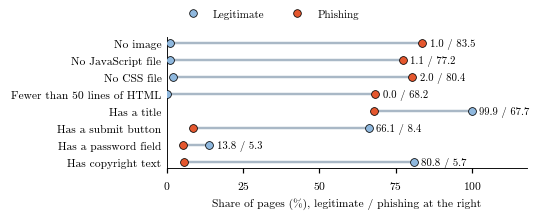

                             legitimate_pct  phishing_pct
No image                               0.96         83.53
No JavaScript file                     1.06         77.23
No CSS file                            1.97         80.41
Fewer than 50 lines of HTML            0.00         68.25
Has a title                           99.88         67.72
Has a submit button                   66.09          8.44
Has a password field                  13.85          5.33
Has copyright text                    80.82          5.72


In [9]:
CHECKS = [   # (chữ trong hình, điều kiện trên mỗi trang)
    ("No image", df.NoOfImage == 0), ("No JavaScript file", df.NoOfJS == 0), ("No CSS file", df.NoOfCSS == 0),
    ("Fewer than 50 lines of HTML", df.LineOfCode < 50), ("Has a title", df.HasTitle == 1), ("Has a submit button", df.HasSubmitButton == 1),
    ("Has a password field", df.HasPasswordField == 1), ("Has copyright text", df.HasCopyrightInfo == 1),
]
page = pd.DataFrame({label: [100 * mask[df.phishing == k].mean() for k in (0, 1)] for label, mask in CHECKS}, index=["legitimate_pct", "phishing_pct"]).T
fig, ax = plt.subplots(figsize=(PAGE_WIDTH, 1.9), layout="constrained")
y = np.arange(len(page))[::-1]
ax.hlines(y, page.legitimate_pct, page.phishing_pct, color=GREY, lw=1.6, zorder=1)
ax.scatter(page.legitimate_pct, y, color=SKY, edgecolor="black", lw=0.5, s=26, zorder=3, label="Legitimate")
ax.scatter(page.phishing_pct, y, color=OURS, edgecolor="black", lw=0.5, s=26, zorder=3, label="Phishing")
for yy, (l, p) in zip(y, page.values):
    ax.text(max(l, p) + 2.5, yy, f"{l:.1f} / {p:.1f}", va="center", fontsize=7)
ax.set_yticks(y)
ax.set_yticklabels(page.index, fontsize=7.5)
ax.set_xlim(0, 118)
ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xlabel("Share of pages (%), legitimate / phishing at the right", fontsize=7.5)
ax.tick_params(axis="y", length=0)
fig.legend(handles=[Line2D([], [], ls="none", marker="o", ms=5, mfc=c, mec="black", mew=0.5, label=l) for c, l in [(SKY, "Legitimate"), (OURS, "Phishing")]],
           loc="outside upper center", ncol=2, fontsize=7.2, frameon=False)
save_paper(fig, "fig_page_empty")
page.round(2).to_csv("../Outputs/table_page_empty.csv", index_label="check")
print(page.round(2).to_string())

## 5.5 Địa lý: bản đồ thế giới theo TLD mã nước (Fig. 3 của bài báo)
**Vì sao chọn dạng này:** câu hỏi "ở đâu" chỉ bản đồ trả lời được trong một cái nhìn. Bảng 32 TLD ở Bước 4, mục 4.12 không cho thấy các TLD trên 50% lừa đảo nằm ở châu Phi, Colombia, Đông Âu và châu Á, còn các TLD dưới 15% lừa đảo phần lớn ở châu Âu, cùng Canada, Nhật, Úc và New Zealand.

Ô dưới tô mỗi nước theo tỷ lệ lừa đảo của TLD mã nước của nước ấy, chỉ cho 32 TLD có từ 500 địa chỉ (cùng ngưỡng với Bước 3 và Bước 4). Nước có TLD dưới 500 địa chỉ tô xám, nước không có địa chỉ nào tô xám nhạt hơn. Hai TLD không ứng với một nước trên bản đồ (`.eu` và `.io`) được ghi bằng chữ.
Bản đồ dùng phép chiếu đồng diện tích Equal Earth (hàm `project` trong ô) để diện tích các nước so được với nhau. Ranh giới nước lấy từ Natural Earth 1:110m (miền công cộng), lưu ở `Data/world_countries.geojson` kèm mã ISO 3166 hai chữ cái.
Cách đọc: đây là nơi ĐĂNG KÝ tên miền, không phải nơi đặt máy chủ hay nơi người lập trang sống (Bước 2, mục 2.8). Ba nước châu Phi `.cf`, `.ml`, `.ga` gần 100% lừa đảo vì từng cho đăng ký tên miền miễn phí (qua Freenom), `.co` 91,5% vì được bán như một tên chung. Ở đầu kia là `.uk` 5,0% và `.jp` 6,2%. Tỷ lệ lừa đảo không đi theo số địa chỉ của TLD (tương quan hạng 0,101).

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


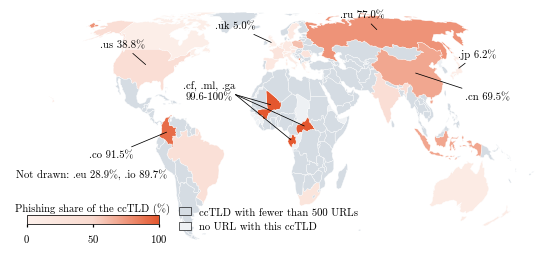

TLD mã nước trong bảng: 231 | từ 500 địa chỉ: 32 | tô được trên bản đồ: 30 | không vẽ được: ['eu', 'io']
       tld_clean                         country  addresses  phishing_pct
iso_a2                                                                   
CF            cf        Central African Republic       1203         100.0
ML            ml                            Mali        994          99.9
GA            ga                           Gabon       1111          99.6
CO            co                        Colombia       5408          91.5
IO            io  British Indian Ocean Territory       4174          89.7
ME            me                      Montenegro        998          84.7
RU            ru              Russian Federation       3870          77.0
ID            id                       Indonesia        801          69.8
CN            cn                           China        992          69.5
PL            pl                          Poland       1329          59.5
IN     

In [10]:
A1, A2, A3, A4 = 1.340264, -0.081106, 0.000893, 0.003796                         # hệ số của phép chiếu Equal Earth (Šavrič và cộng sự, 2018)


def project(lon, lat):
    """Phép chiếu đồng diện tích Equal Earth: kinh độ, vĩ độ (độ) sang toạ độ phẳng."""
    lam, phi = np.radians(np.asarray(lon, float)), np.radians(np.asarray(lat, float))
    theta = np.arcsin(np.sqrt(3) / 2 * np.sin(phi))
    x = 2 * np.sqrt(3) * lam * np.cos(theta) / (3 * (9 * A4 * theta ** 8 + 7 * A3 * theta ** 6 + 3 * A2 * theta ** 2 + A1))
    y = A4 * theta ** 9 + A3 * theta ** 7 + A2 * theta ** 3 + A1 * theta
    return x, y


world = json.load(open("../Data/world_countries.geojson", encoding="utf-8"))["features"]
cc = df[df.tld_type == "country code"].groupby(["tld_clean", "country"]).phishing.agg(addresses="size", phishing_pct="mean").reset_index()
cc["phishing_pct"] *= 100
cc["iso_a2"] = cc.tld_clean.str.upper().replace({"UK": "GB"})                   # TLD .uk ứng với mã nước GB
big = cc[cc.addresses >= 500].set_index("iso_a2")                               # cùng ngưỡng 500 địa chỉ với Bước 3 và Bước 4
small = set(cc[cc.addresses < 500].iso_a2)
on_map = {f["properties"]["iso_a2"] for f in world}
fig = plt.figure(figsize=(PAGE_WIDTH, 2.3))
ax = fig.add_axes([0, 0, 1, 1])
patches, colors = [], []
for f in world:
    code, geom = f["properties"]["iso_a2"], f["geometry"]
    polygons = geom["coordinates"] if geom["type"] == "MultiPolygon" else [geom["coordinates"]]
    color = CMAP_CORAL(big.loc[code, "phishing_pct"] / 100) if code in big.index else "#D5DCE3" if code in small else "#EEF1F4"
    for polygon in polygons:
        ring = np.array(polygon[0])
        px, py = project(ring[:, 0], ring[:, 1])
        patches.append(Polygon(np.column_stack([px, py]), closed=True))
        colors.append(color)
ax.add_collection(PatchCollection(patches, facecolor=colors, edgecolor="white", lw=0.25))
ax.set_xlim(project(-180, 0)[0], project(180, 0)[0])
ax.set_ylim(project(0, -58)[1], project(0, 84)[1])
ax.set_aspect("equal")
ax.axis("off")
LABELS = {"CO": (-112, -8), "RU": (95, 78), "CN": (150, 22), "GB": (-38, 66), "JP": (162, 46), "US": (-128, 52)}
POINTS = {"CO": (-73, 4), "RU": (95, 62), "CN": (104, 35), "GB": (-2, 53), "JP": (138, 37), "US": (-98, 39)}
for code, (lx, ly) in LABELS.items():
    ax.annotate(f".{big.loc[code, 'tld_clean']} {big.loc[code, 'phishing_pct']:.1f}%", xy=project(*POINTS[code]), xytext=project(lx, ly), fontsize=7, ha="center", va="center",
                arrowprops=dict(arrowstyle="-", color="black", lw=0.5, shrinkA=1, shrinkB=1))
ax.text(*project(-47, 25), ".cf, .ml, .ga\n99.6-100%", fontsize=7, ha="center", va="center")                  # ba TLD châu Phi dùng chung một nhãn
for lon, lat in [(-2, 17.5), (21, 6.5), (11.7, -0.7)]:                                                         # Mali, Cộng hoà Trung Phi, Gabon
    ax.annotate("", xy=project(lon, lat), xytext=project(-28, 23), arrowprops=dict(arrowstyle="-", color="black", lw=0.5, shrinkA=0, shrinkB=1))
missing = big[~big.index.isin(on_map)]
ax.text(0.01, 0.30, "Not drawn: " + ", ".join(f".{r.tld_clean} {r.phishing_pct:.1f}%" for _, r in missing.iterrows()), transform=ax.transAxes, fontsize=7, ha="left", va="center")
bar_ax = fig.add_axes([0.03, 0.12, 0.25, 0.035])
bar = fig.colorbar(plt.cm.ScalarMappable(cmap=CMAP_CORAL, norm=plt.Normalize(0, 100)), cax=bar_ax, orientation="horizontal")
bar.set_ticks([0, 50, 100])
bar.ax.tick_params(labelsize=7, length=2)
bar.outline.set_linewidth(0.5)
bar_ax.set_title("Phishing share of the ccTLD (%)", fontsize=7, pad=2)
fig.legend(handles=[Patch(facecolor="#D5DCE3", edgecolor="black", lw=0.4, label="ccTLD with fewer than 500 URLs"), Patch(facecolor="#EEF1F4", edgecolor="black", lw=0.4, label="no URL with this ccTLD")],
           loc="lower left", bbox_to_anchor=(0.30, 0.05), fontsize=7, frameon=False, handlelength=1.1)
save_paper(fig, "fig_map")
cc.sort_values("addresses", ascending=False).round(2).to_csv("../Outputs/table_map_cctld.csv", index=False)
print("TLD mã nước trong bảng:", len(cc), "| từ 500 địa chỉ:", len(big), "| tô được trên bản đồ:", int(big.index.isin(on_map).sum()), "| không vẽ được:", missing.tld_clean.tolist())
print(big.sort_values("phishing_pct", ascending=False)[["tld_clean", "country", "addresses", "phishing_pct"]].round(1).to_string())

## 5.6 Chu kỳ: thứ tự dòng trong tệp (chỉ trong notebook)
**Vì sao chọn dạng này:** bộ dữ liệu không có cột ngày, giờ hay năm, nên không vẽ được mùa vụ. Câu hỏi gần nhất là tệp có được ghép theo từng đợt thu thập hay không. Bản đồ nhiệt bốn chỉ số x 24 khối dòng cho thấy cùng lúc mọi khối và mọi chỉ số.

Ô dưới chia tệp (đã bỏ trùng, giữ đúng thứ tự gốc) thành 24 khối 10.000 dòng (khối cuối 5.370 dòng) và tính bốn tỷ lệ trong từng khối: lừa đảo, trang chủ, bắt đầu bằng `https://www.`, và TLD mã nước. Số trong ô là tỷ lệ của khối. Màu là chênh lệch so với tỷ lệ của cả tệp (ghi trong ngoặc ở nhãn hàng): xanh là thấp hơn, san hô là cao hơn, trắng là bằng.
Cách đọc: nếu tệp ghép theo đợt thì sẽ có những dải màu đậm liền nhau. Hình gần như trắng: tỷ lệ lừa đảo chỉ chạy từ 38,51% tới 44,17% (độ lệch chuẩn 1,12 điểm), tỷ lệ TLD mã nước từ 28,57% tới 30,09%. Chỉ bốn khối đầu có nhiều trang chủ hơn (77% tới 83% so với 74,51%). Tệp đã được trộn, nên không có chu kỳ hay thứ tự để khai thác.

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


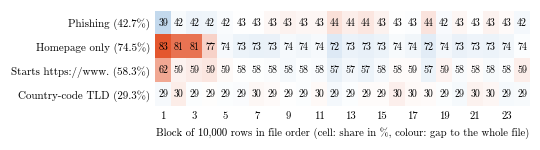

Số khối: 24 | khối cuối có 5370 dòng
                     toàn tệp  thấp nhất  cao nhất  độ lệch chuẩn
Phishing                42.71      38.51     44.17           1.12
Homepage only           74.51      72.10     82.57           2.86
Starts https://www.     58.33      56.80     62.43           1.12
Country-code TLD        29.26      28.57     30.09           0.44


In [12]:
BLOCK = 10_000
order = df.sort_values("row_id").reset_index(drop=True)                         # đúng thứ tự dòng của tệp gốc sau khi bỏ trùng
order["block"] = order.index // BLOCK
ROWS = [("Phishing", "phishing"), ("Homepage only", "homepage_only"), ("Starts https://www.", "starts_https_www"), ("Country-code TLD", "is_cc")]
order["is_cc"] = (order.tld_type == "country code").astype(int)
share = order.groupby("block")[[c for _, c in ROWS]].mean().T * 100             # mỗi hàng một chỉ số, mỗi cột một khối 10.000 dòng
overall = order[[c for _, c in ROWS]].mean() * 100
gap = share.sub(overall, axis=0)                                                # chênh với mức chung của cả tệp, đơn vị điểm phần trăm
fig, ax = plt.subplots(figsize=(PAGE_WIDTH, 1.25), layout="constrained")
ax.imshow(gap.values, cmap=CMAP_DIVERGE, vmin=-8, vmax=8, aspect="auto")
for i in range(gap.shape[0]):
    for j in range(gap.shape[1]):
        ax.text(j, i, f"{share.values[i, j]:.0f}", ha="center", va="center", fontsize=6.5)
ax.set_yticks(range(len(ROWS)))
ax.set_yticklabels([f"{label} ({overall[c]:.1f}%)" for label, c in ROWS], fontsize=7.2)
ax.set_xticks(range(0, gap.shape[1], 2))
ax.set_xticklabels([str(k + 1) for k in range(0, gap.shape[1], 2)], fontsize=7)
ax.set_xlabel("Block of 10,000 rows in file order (cell: share in %, colour: gap to the whole file)", fontsize=7)
ax.tick_params(length=0)
for side in ["left", "bottom", "top", "right"]:
    ax.spines[side].set_visible(False)
save_paper(fig, "fig_file_order")
share.index = [label for label, _ in ROWS]
share.round(2).to_csv("../Outputs/table_file_order_blocks.csv")
print("Số khối:", share.shape[1], "| khối cuối có", len(order) - BLOCK * (share.shape[1] - 1), "dòng")
print(pd.DataFrame({"toàn tệp": overall.values, "thấp nhất": share.min(axis=1).values, "cao nhất": share.max(axis=1).values, "độ lệch chuẩn": share.std(axis=1).values}, index=share.index).round(2).to_string())

## 5.7 Phân bố: độ dài địa chỉ và độ lớn trang ở ba nhóm (Fig. 4 của bài báo)
**Vì sao chọn dạng này:** trung bình che mất độ phân tán, nên dùng biểu đồ hộp. Hai khung đặt cạnh nhau, cùng ba nhóm, để so một đặc trưng địa chỉ với một đặc trưng trang. Cả hai trục ngang dùng thang log vì hai đặc trưng lệch phải rất mạnh (Bước 4, mục 4.1).

Ô dưới vẽ cho ba nhóm (hợp lệ, lừa đảo là trang chủ, lừa đảo có đường dẫn) hai biểu đồ hộp: (a) độ dài địa chỉ sau khi cắt `http(s)://` và `www.`, (b) số dòng HTML cộng 1 (để trang 0 dòng vẫn lấy được log).
Cách đọc: hộp chứa nửa giữa của dữ liệu (phân vị 25% tới 75%), vạch trong hộp là trung vị, râu kéo từ phân vị 5% tới 95%. Không vẽ điểm ngoại lai vì có hơn 235.000 địa chỉ.
Ở khung (a), hộp hợp lệ (12 tới 18 ký tự) và hộp lừa đảo là trang chủ (12 tới 20 ký tự) gần như trùng nhau, cùng trung vị 15: độ dài chỉ tách được nhóm có đường dẫn (trung vị 35). Ở khung (b), ba hộp tách hẳn nhau: trang hợp lệ có trung vị 1.105 dòng và 95% trang hợp lệ có từ 265 dòng trở lên, còn trang lừa đảo là trang chủ có trung vị 8 dòng. Đặc trưng trang tách hai lớp ở mọi nhóm, nhưng đó là dấu vết của cách lưu trang, không phải của địa chỉ.

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


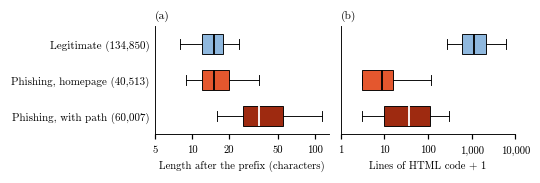

Hộp: phân vị 25% tới 75%, vạch giữa là trung vị, râu từ phân vị 5% tới 95%:
   feature               group      n   p05    q1  median     q3    p95
 pb_length Phishing, with path  60007  16.0  26.0    35.0   55.0  113.0
 pb_length  Phishing, homepage  40513   9.0  12.0    15.0   20.0   35.0
 pb_length          Legitimate 134850   8.0  12.0    15.0   18.0   24.0
LineOfCode Phishing, with path  60007   2.0   9.0    36.0  108.0  299.0
LineOfCode  Phishing, homepage  40513   2.0   2.0     8.0   15.0  116.0
LineOfCode          Legitimate 134850 265.0 613.0  1105.0 2088.0 6071.5


In [15]:
PANELS = [   # (cột, chữ trục ngang, cộng 1 trước khi lấy log hay không, vạch chia)
    ("pb_length", "Length after the prefix (characters)", False, [5, 10, 20, 50, 100]),
    ("LineOfCode", "Lines of HTML code + 1", True, [1, 10, 100, 1000, 10000]),
]
fig, axes = plt.subplots(1, 2, figsize=(PAGE_WIDTH, 1.55), layout="constrained", sharey=True)
distribution = []
for ax, (col, xlabel, plus_one, ticks) in zip(axes, PANELS):
    for k, g in enumerate(GROUPS[::-1]):
        values = df.loc[df.group == g, col].to_numpy()
        ax.boxplot(np.log10(values + 1 if plus_one else values), positions=[k], widths=0.55, orientation="horizontal", patch_artist=True, whis=(5, 95), showfliers=False,
                   boxprops=dict(facecolor=GROUP_COLOR[g], edgecolor="black", lw=0.6), medianprops=dict(color="white" if g == GROUPS[2] else "black", lw=1.2),
                   whiskerprops=dict(color="black", lw=0.6), capprops=dict(color="black", lw=0.6))
        distribution.append(dict(feature=col, group=g, n=len(values), p05=np.percentile(values, 5), q1=np.percentile(values, 25), median=np.median(values),
                                 q3=np.percentile(values, 75), p95=np.percentile(values, 95)))
    ax.set_xticks(np.log10(ticks))
    ax.set_xticklabels([f"{t:,}" for t in ticks], fontsize=7)
    ax.set_xlabel(xlabel, fontsize=7)
    ax.tick_params(axis="y", length=0)
axes[0].set_yticks(range(3))
axes[0].set_yticklabels([f"{g} ({(df.group == g).sum():,})" for g in GROUPS[::-1]], fontsize=7.2)
panel(axes[0], "(a)")
panel(axes[1], "(b)")
save_paper(fig, "fig_distribution")
distribution = pd.DataFrame(distribution)
distribution.round(2).to_csv("../Outputs/table_distribution.csv", index=False)
print("Hộp: phân vị 25% tới 75%, vạch giữa là trung vị, râu từ phân vị 5% tới 95%:")
print(distribution.round(1).to_string(index=False))

## 5.8 Bảy bộ đặc trưng gồm những gì (Fig. 5 của bài báo)
**Vì sao chọn dạng này:** câu hỏi nghiên cứu 3 bỏ dần từng nhóm cột, nên người đọc cần thấy mỗi bộ gồm những nhóm nào và còn bao nhiêu cột. Cột ngang xếp chồng theo nhóm cho thấy cả hai điều trong một hình.

Ô dưới chia 50 cột của tác giả thành năm nhóm: chỉ số tương đồng (1 cột), cột địa chỉ mang thông tin tiền tố (`IsHTTPS` và `NoOfSubDomain`, vì cột này đếm cả `www.`), hai cột thống kê TLD, 17 cột địa chỉ còn lại và 28 cột trang. Nhóm thứ sáu là 14 cột không thấy tiền tố do nhóm tự tính. Mỗi bộ đặc trưng là một cột ngang, số trong đoạn là số cột của nhóm ấy. Cột chữ bên phải cho biết bộ có thấy tiền tố hay không.
Cách đọc: năm bộ đầu đều còn hai cột mang tiền tố, kể cả bộ S5 đã bỏ thống kê TLD. Bộ S6 không thấy tiền tố nhưng có 28 cột trang, vốn là một lối tắt khác (mục 5.4). Chỉ bộ S7 vừa không thấy tiền tố vừa không có cột trang.

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


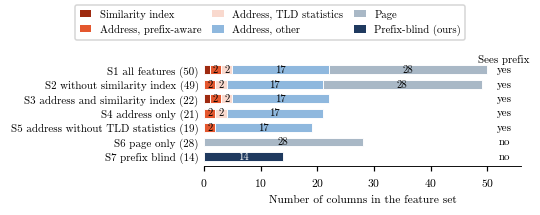

                                   Similarity index  Address, prefix-aware  Address, TLD statistics  Address, other  Page  Prefix-blind (ours)  total
S1 all features                                   1                      2                        2              17    28                    0     50
S2 without similarity index                       0                      2                        2              17    28                    0     49
S3 address and similarity index                   1                      2                        2              17     0                    0     22
S4 address only                                   0                      2                        2              17     0                    0     21
S5 address without TLD statistics                 0                      2                        0              17     0                    0     19
S6 page only                                      0                      0                        0 

In [18]:
ADDRESS = groups["address"]
PREFIX_AWARE = ["IsHTTPS", "NoOfSubDomain"]                                     # hai cột mang thông tin tiền tố (Bước 2, mục 2.5)
TLD_STATS = ["TLDLegitimateProb", "URLCharProb"]
OTHER_ADDRESS = [c for c in ADDRESS if c not in PREFIX_AWARE + TLD_STATS]
PARTS = [   # (chữ trong chú thích, danh sách cột, màu)
    ("Similarity index", groups["shortcut"], DARK), ("Address, prefix-aware", PREFIX_AWARE, OURS), ("Address, TLD statistics", TLD_STATS, OURS_L),
    ("Address, other", OTHER_ADDRESS, SKY), ("Page", groups["page"], GREY), ("Prefix-blind (ours)", groups["prefix_blind"], NAVY),
]
SETS = {
    "S1 all features": groups["shortcut"] + ADDRESS + groups["page"], "S2 without similarity index": ADDRESS + groups["page"],
    "S3 address and similarity index": groups["shortcut"] + ADDRESS, "S4 address only": ADDRESS,
    "S5 address without TLD statistics": [c for c in ADDRESS if c not in TLD_STATS], "S6 page only": groups["page"], "S7 prefix blind": groups["prefix_blind"],
}
composition = pd.DataFrame({name: [len(set(cols) & set(part)) for _, part, _ in PARTS] for name, cols in SETS.items()}, index=[label for label, _, _ in PARTS]).T
fig, ax = plt.subplots(figsize=(PAGE_WIDTH, 1.85), layout="constrained")
y = np.arange(len(SETS))[::-1]
for yy, (name, row) in zip(y, composition.iterrows()):
    left = 0
    for (label, _, color), n in zip(PARTS, row):
        if n:
            ax.barh(yy, n, left=left, height=0.62, color=color, edgecolor="white", lw=0.6)
            if n >= 2:
                ax.text(left + n / 2, yy, str(n), ha="center", va="center", fontsize=7, color="white" if color in (DARK, NAVY) else "black")
        left += n
    sees = "yes" if row["Address, prefix-aware"] or row["Similarity index"] else "no"
    ax.text(53, yy, sees, ha="center", va="center", fontsize=7.2)
ax.text(53, y[0] + 0.75, "Sees prefix", ha="center", va="center", fontsize=7.2)
ax.set_yticks(y)
ax.set_yticklabels([f"{name} ({len(cols)})" for name, cols in SETS.items()], fontsize=7.2)
ax.set_xlim(0, 56)
ax.set_xticks([0, 10, 20, 30, 40, 50])
ax.set_xlabel("Number of columns in the feature set", fontsize=7.5)
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
fig.legend(handles=[Patch(facecolor=c, label=l) for l, _, c in PARTS], loc="outside upper center", ncol=3, fontsize=7, handlelength=1.1, columnspacing=1.0)
save_paper(fig, "fig_feature_sets")
composition.to_csv("../Outputs/table_feature_set_composition.csv", index_label="feature_set")
print(composition.assign(total=composition.sum(axis=1)).to_string())

## 5.9 Mười mô hình trên bảy bộ đặc trưng, nhóm trang chủ (Fig. 6 của bài báo)
**Vì sao chọn dạng này:** kết quả có hai chiều là mô hình và bộ đặc trưng, tức 70 con số. Bản đồ nhiệt là bảng số được tô màu: mắt thấy ngay cột nào nhạt, rồi đọc số trong ô để biết chính xác. Hình đọc kết quả đã lưu của Bước 6 (`Outputs/results_ladder.csv`), không huấn luyện lại.

Ô dưới lấy tỷ lệ địa chỉ lừa đảo là trang chủ bị bắt ở mức 1% báo động giả, trung bình năm seed, cho mỗi mô hình và mỗi bộ đặc trưng. Hàng xếp theo kết quả ở bộ S7 giảm dần, khe trắng tách bộ S7 khỏi sáu bộ còn lại, số của bộ S7 in đậm.
Cách đọc: sáu cột đầu đậm đều, mọi mô hình bắt trên 98% địa chỉ lừa đảo là trang chủ. Cột S7 nhạt hẳn: mô hình tốt nhất chỉ bắt khoảng 26%, hai mô hình tuyến tính khoảng 15%. Khác biệt giữa các mô hình nhỏ hơn rất nhiều so với khác biệt giữa các bộ đặc trưng: điểm số nằm ở đặc trưng, không nằm ở mô hình.

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


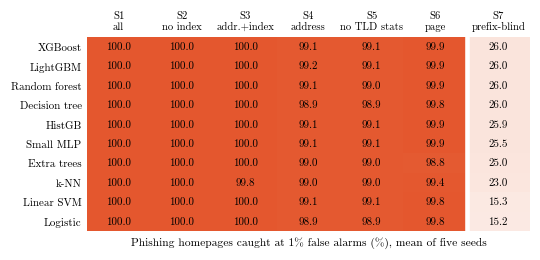

feature_set    S1 all features  S2 without similarity index  S3 address and similarity index  S4 address only  S5 address without TLD statistics  S6 page only  S7 prefix blind
model                                                                                                                                                                          
XGBoost                  100.0                        100.0                            100.0             99.1                               99.1          99.9             26.0
LightGBM                 100.0                        100.0                            100.0             99.2                               99.1          99.9             26.0
Random forest            100.0                        100.0                            100.0             99.1                               99.0          99.9             26.0
Decision tree            100.0                        100.0                            100.0             98.9           

In [20]:
home = ladder.groupby(["model", "feature_set"]).home_caught.mean().unstack("feature_set")[list(SETS)] * 100
home = home.sort_values("S7 prefix blind", ascending=False)
SHORT = ["S1\nall", "S2\nno index", "S3\naddr.+index", "S4\naddress", "S5\nno TLD stats", "S6\npage", "S7\nprefix-blind"]
fig, ax = plt.subplots(figsize=(PAGE_WIDTH, 2.25), layout="constrained")
ax.imshow(home.values, cmap=CMAP_CORAL, vmin=0, vmax=100, aspect="auto")
for i in range(home.shape[0]):
    for j in range(home.shape[1]):
        value = home.values[i, j]
        ax.text(j, i, f"{value:.1f}", ha="center", va="center", fontsize=7.2, fontfamily=BOLD if j == home.shape[1] - 1 else None)
ax.axvline(home.shape[1] - 1.5, color="white", lw=3)                            # khe trắng tách bộ không thấy tiền tố
ax.set_xticks(range(home.shape[1]))
ax.set_xticklabels(SHORT, fontsize=7)
ax.set_yticks(range(home.shape[0]))
ax.set_yticklabels(home.index, fontsize=7.2)
ax.xaxis.tick_top()
ax.tick_params(length=0)
for side in ["left", "bottom", "top", "right"]:
    ax.spines[side].set_visible(False)
ax.set_xlabel("Phishing homepages caught at 1% false alarms (%), mean of five seeds", fontsize=7.5)
save_paper(fig, "fig_models_heatmap")
home.round(2).to_csv("../Outputs/table_models_homepage_caught.csv")
print(home.round(1).to_string())

## 5.10 Bảng mô tả ba nhóm địa chỉ (bảng của bài báo)
Ô dưới tính chín con số cho ba nhóm và cho cả bảng: số địa chỉ, tỷ lệ bắt đầu bằng `https://www.`, tỷ lệ dùng HTTPS, tỷ lệ có chỉ số tương đồng bằng 100, trung vị độ dài sau khi cắt tiền tố, trung vị số dòng HTML, tỷ lệ trang không có ảnh, tỷ lệ TLD mã nước, và tỷ lệ địa chỉ dùng chung tên miền đăng ký với địa chỉ khác.
Bảng được ghi ra `Outputs/table_groups.csv` và `Paper/tables/table_groups.tex`.
Cách đọc: mỗi cột của bảng LaTeX là một nhóm. Ba hàng đầu (tiền tố, HTTPS, chỉ số tương đồng) và hàng số dòng HTML là các lối tắt: hợp lệ và lừa đảo khác nhau gần như tuyệt đối. Hàng độ dài sau tiền tố và hàng TLD mã nước thì hợp lệ và lừa đảo là trang chủ gần như bằng nhau. Hàng tên miền dùng chung giải thích vì sao Bước 6 thêm cách chia theo tên miền.

In [23]:
domain_size = df.reg_domain.map(df.reg_domain.value_counts())
MEASURES = [   # (chữ trong bảng, hàm tính trên một nhóm, định dạng)
    ("URLs", lambda g: len(g), "{:,.0f}"),
    ("Starts with https://www. (\\%)", lambda g: 100 * g.starts_https_www.mean(), "{:.1f}"),
    ("Uses HTTPS (\\%)", lambda g: 100 * g.IsHTTPS.mean(), "{:.1f}"),
    ("Similarity index = 100 (\\%)", lambda g: 100 * (g.URLSimilarityIndex >= 100).mean(), "{:.1f}"),
    ("Median length after prefix", lambda g: g.pb_length.median(), "{:.0f}"),
    ("Median lines of HTML", lambda g: g.LineOfCode.median(), "{:,.0f}"),
    ("No image on the page (\\%)", lambda g: 100 * (g.NoOfImage == 0).mean(), "{:.1f}"),
    ("Country-code TLD (\\%)", lambda g: 100 * (g.tld_type == "country code").mean(), "{:.1f}"),
    ("Domain shared with other URLs (\\%)", lambda g: 100 * (domain_size[g.index] > 1).mean(), "{:.1f}"),
]
profile = pd.DataFrame({g: [f(df[df.group == g]) for _, f, _ in MEASURES] for g in GROUPS}, index=[label for label, _, _ in MEASURES])
profile["All URLs"] = [f(df) for _, f, _ in MEASURES]
profile.to_csv("../Outputs/table_groups.csv", index_label="measure")
lines = ["\\begin{tabular}{lrrrr}", "\\toprule", " & & \\multicolumn{2}{c}{Phishing} & \\\\", "\\cmidrule(lr){3-4}",
         "Measure & Legitimate & Homepage & With path & All URLs \\\\", "\\midrule"]
for (label, _, fmt), (_, row) in zip(MEASURES, profile.iterrows()):
    lines.append(label + " & " + " & ".join(fmt.format(v) for v in row.values) + " \\\\")
lines += ["\\bottomrule", "\\end{tabular}"]
open("../Paper/tables/table_groups.tex", "w").write("\n".join(lines) + "\n")
print(profile.T.round(2).to_string())

                         URLs  Starts with https://www. (\%)  Uses HTTPS (\%)  Similarity index = 100 (\%)  Median length after prefix  Median lines of HTML  No image on the page (\%)  Country-code TLD (\%)  Domain shared with other URLs (\%)
Legitimate           134850.0                         100.00           100.00                       100.00                        15.0                1105.0                       0.96                  29.60                                3.77
Phishing, homepage    40513.0                           1.55             5.61                         1.87                        15.0                   8.0                      95.48                  30.90                               30.17
Phishing, with path   60007.0                           3.03            78.50                         0.05                        35.0                  36.0                      75.47                  27.40                               83.59
All URLs             235370.

## 5.11 Lưu các con số của mục Data và mục mô tả để dò với bài báo
Ô dưới gom các con số mà phần dữ liệu và phần mô tả của bài báo nhắc tới (kích thước tệp, số dòng trùng, số địa chỉ mỗi lớp và mỗi nhóm, số cột mỗi nhóm đặc trưng, loại TLD, tên miền đăng ký) và lưu vào `Outputs/paper_numbers_data.csv`.
Cách đọc: mỗi dòng là một con số kèm tên mục của bài báo. Khi sửa câu văn, hãy dò từng số với bảng này.

In [24]:
D, S = "3 Data", "4 Descriptive findings"
raw = pd.read_csv("../Data/PhiUSIIL_Phishing_URL_Dataset.csv", low_memory=False)
note(D, "Rows x columns of PhiUSIIL_Phishing_URL_Dataset.csv", f"{raw.shape[0]} x {raw.shape[1]}")
note(D, "Duplicate URLs removed, rows kept", f"{raw.shape[0] - len(df)}, {len(df)}")
note(D, "Model table rows x columns", f"{df.shape[0]} x {df.shape[1] - 1}")
note(D, "Legitimate, phishing URLs after cleaning", f"{(df.phishing == 0).sum()}, {(df.phishing == 1).sum()}")
note(D, "Homepage-only URLs: all, legitimate, phishing", f"{int(df.homepage_only.sum())}, {int(df.homepage_only[df.phishing == 0].sum())}, {int(df.homepage_only[df.phishing == 1].sum())}")
note(D, "Phishing URLs with a path", int(((df.phishing == 1) & (df.homepage_only == 0)).sum()))
note(D, "Feature groups: similarity, address, page, prefix-blind", ", ".join(str(len(groups[k])) for k in ["shortcut", "address", "page", "prefix_blind"]))
note(D, "TLD types: generic, country code, IP address", ", ".join(str(int((df.tld_type == t).sum())) for t in ["generic", "country code", "ip address"]))
note(D, "Registered domains: all, with more than one URL", f"{df.reg_domain.nunique()}, {int((df.reg_domain.value_counts() > 1).sum())}")
note(D, "Seen TLDs (com, org, net): share of URLs %", round(100 * df.tld_seen.mean(), 2))
for g in GROUPS:
    r = profile[g]
    note(S, f"{g}: starts https://www. %, HTTPS %, similarity = 100 %, median length after prefix, median lines of HTML",
         f"{r.iloc[1]:.2f}, {r.iloc[2]:.2f}, {r.iloc[3]:.2f}, {r.iloc[4]:.0f}, {r.iloc[5]:.0f}")
numbers = pd.DataFrame(NUMBERS)
numbers.to_csv("../Outputs/paper_numbers_data.csv", index=False)
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 120)
print("Đã ghi", len(numbers), "con số vào Outputs/paper_numbers_data.csv")
print(numbers.to_string(index=False))

Đã ghi 13 con số vào Outputs/paper_numbers_data.csv
         paper_section                                                                                                                  quantity                            value
                3 Data                                                                       Rows x columns of PhiUSIIL_Phishing_URL_Dataset.csv                      235795 x 56
                3 Data                                                                                         Duplicate URLs removed, rows kept                      425, 235370
                3 Data                                                                                                Model table rows x columns                      235370 x 89
                3 Data                                                                                  Legitimate, phishing URLs after cleaning                   134850, 100520
                3 Data                                    

## 5.12 Lưu các con số của các hình
Ô dưới gom các con số mà bài báo trích từ các hình của mục 5.2 tới 5.9 (dạng địa chỉ, trang trống, bản đồ, thứ tự trong tệp, phân bố, bản đồ nhiệt mô hình) rồi lưu vào `Outputs/paper_numbers_eda.csv`. Tệp `paper_numbers_data.csv` của mục 5.11 được giữ nguyên.
Cách đọc: mỗi dòng là một con số kèm tên mục của bài báo. Khi sửa câu văn về một hình, hãy dò từng số với bảng này.

In [26]:
EDA = []
F, G, C, P, M = "4 Descriptive findings (shapes)", "4 Descriptive findings (map)", "4 Descriptive findings (file order)", "4 Descriptive findings (distribution)", "5 Results (heatmap)"


def note_eda(section, name, value):
    EDA[:] = [r for r in EDA if not (r["paper_section"] == section and r["quantity"] == name)]
    EDA.append(dict(paper_section=section, quantity=name, value=value))


note_eda(F, "Phishing URLs by shape %: https://www. no path, https://www. with path, other no path, other with path", ", ".join(f"{v:.2f}" for v in shape_table.loc["Phishing"]))
note_eda(F, "Legitimate URLs starting https://www. without a path %", round(shape_table.loc["Legitimate", SHAPES[0][0]], 2))
note_eda(F, "Phishing URLs with similarity index = 100 %", round(100 * (df.URLSimilarityIndex[df.phishing == 1] >= 100).mean(), 2))
for label in page.index:
    note_eda(F, f"Pages: {label} %, legitimate and phishing", f"{page.loc[label, 'legitimate_pct']:.1f}, {page.loc[label, 'phishing_pct']:.1f}")
note_eda(G, "Country-code TLDs: all, with at least 500 URLs, drawn on the map", f"{len(cc)}, {len(big)}, {int(big.index.isin(on_map).sum())}")
note_eda(G, "ccTLDs with at least 500 URLs above 50% phishing, below 15%", f"{int((big.phishing_pct > 50).sum())}, {int((big.phishing_pct < 15).sum())}")
note_eda(G, "ccTLDs not drawn (not one country on the map)", ", ".join(f".{r.tld_clean} {r.phishing_pct:.1f}" for _, r in missing.iterrows()))
for code in ["CF", "ML", "GA", "CO", "RU", "CN", "US", "GB", "JP"]:
    note_eda(G, f".{big.loc[code, 'tld_clean']}: URLs, phishing %", f"{big.loc[code, 'addresses']}, {big.loc[code, 'phishing_pct']:.1f}")
note_eda(G, "Spearman correlation of ccTLD size and phishing share (ccTLDs with 500+ URLs)", round(big.addresses.corr(big.phishing_pct, method="spearman"), 3))
for label in share.index:
    note_eda(C, f"{label} by block of 10,000 rows %: whole file, lowest, highest, standard deviation",
             f"{overall.iloc[list(share.index).index(label)]:.2f}, {share.loc[label].min():.2f}, {share.loc[label].max():.2f}, {share.loc[label].std():.2f}")
for _, r in distribution.iterrows():
    note_eda(P, f"{r.feature}, {r.group}: 5%, 25%, median, 75%, 95%", f"{r.p05:.0f}, {r.q1:.0f}, {r['median']:.0f}, {r.q3:.0f}, {r.p95:.0f}")
note_eda(M, "Homepage caught at 1% false alarms %, S1 to S6: lowest over models and sets", round(home.iloc[:, :-1].values.min(), 2))
note_eda(M, "Homepage caught at 1% false alarms %, S7: lowest, highest model", f"{home.iloc[:, -1].min():.2f} ({home.iloc[:, -1].idxmin()}), {home.iloc[:, -1].max():.2f} ({home.iloc[:, -1].idxmax()})")
eda = pd.DataFrame(EDA)
eda.to_csv("../Outputs/paper_numbers_eda.csv", index=False)
print("Đã ghi", len(eda), "con số vào Outputs/paper_numbers_eda.csv")
print(eda.to_string(index=False))

Đã ghi 36 con số vào Outputs/paper_numbers_eda.csv
                        paper_section                                                                                               quantity                             value
      4 Descriptive findings (shapes) Phishing URLs by shape %: https://www. no path, https://www. with path, other no path, other with path          0.62, 1.81, 39.68, 57.89
      4 Descriptive findings (shapes)                                                 Legitimate URLs starting https://www. without a path %                             100.0
      4 Descriptive findings (shapes)                                                            Phishing URLs with similarity index = 100 %                              0.78
      4 Descriptive findings (shapes)                                                             Pages: No image %, legitimate and phishing                         1.0, 83.5
      4 Descriptive findings (shapes)                                     

**Tóm tắt Bước 5.** Bảng dưới gom các hình và bảng cho bài báo. Hình PDF nằm trong `Paper/figs`, bản PNG xem nhanh nằm trong `Figures`.

| STT | Tệp | Trong bài báo | Ý chính |
|---|---|---|---|
| 1 | `fig_pipeline.pdf` | Fig. 1 | Sáu tầng của nghiên cứu, phần san hô là đóng góp |
| 2 | `fig_url_shapes.pdf` | Fig. 2 | Hợp lệ 100% là `https://www.` không đường dẫn, lừa đảo chỉ 0,62% |
| 3 | `fig_map.pdf` | Fig. 3 | TLD trên 50% lừa đảo ở châu Phi, Colombia, Đông Âu, châu Á; dưới 15% phần lớn ở châu Âu, Canada, Nhật, Úc |
| 4 | `fig_distribution.pdf` | Fig. 4 | Độ dài chồng nhau ở trang chủ, số dòng HTML thì tách hẳn |
| 5 | `fig_feature_sets.pdf` | Fig. 5 | Năm bộ đầu còn thấy tiền tố, chỉ S7 không thấy tiền tố và không có cột trang |
| 6 | `fig_models_heatmap.pdf` | Fig. 6 | Trên trang chủ, mọi mô hình sụp cùng nhau ở S7 |
| 7 | `fig_similarity.pdf`, `fig_page_empty.pdf`, `fig_file_order.pdf` | Slide | Chỉ số tương đồng, trang trống, tệp đã trộn |
| 8 | `table_groups.tex` | Bảng mô tả | Ba nhóm địa chỉ, chín con số |

Ba góc nhìn của môn học: địa lý là bản đồ TLD mã nước (mục 5.5), chu kỳ được thay bằng thứ tự trong tệp vì dữ liệu không có thời gian (mục 5.6), phân bố là biểu đồ hộp ba nhóm (mục 5.7).